# Imports

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import base64
import seaborn as sns

In [2]:
import ratinabox
from ratinabox.Environment import Environment
from ratinabox.Agent import Agent
from ratinabox.Neurons import FieldOfViewOVCs
# from ratinabox.Neurons import PlaceCells, GridCells #...

## aux funcs

In [3]:
import random
import string

def generate_random_string(n):
    """
    Generate a random string of length n.

    Parameters:
    n (int): The desired length of the string.

    Returns:
    str: A random string of length n.
    """
    if n <= 0:
        raise ValueError("Length 'n' must be a positive integer.")

    # Combine letters, digits, and punctuation
    characters = string.ascii_uppercase
    
    # Generate a random string of length n
    random_string = ''.join(random.choices(characters, k=n))

    return random_string


In [4]:
generate_random_string(8)

'ASYAFBKZ'

In [5]:
def generate_all_positions_on_env(hole=None):

        # Define the range and step size
    step = 0.001  # Adjust the step size for granularity
    x_range = np.arange(0, 1 + step, step)
    y_range = np.arange(0, 1 + step, step)

    # Create a grid of (x, y) positions
    x, y = np.meshgrid(x_range, y_range)
    positions = np.column_stack([x.ravel(), y.ravel()])

    # Convert to a pandas DataFrame
    df_positions = pd.DataFrame(positions, columns=["X", "Y"])
    # df_positions['is_valid'] = [int(is_point_valid(pos, hole)) for pos in positions]
    df_positions['pos'] = [val for val in positions]

    return df_positions

In [6]:
def get_euclidean_distance(pos1, pos2):
    return np.sqrt((pos1[0] - pos2[0])**2 + ((pos1[1] - pos2[1])**2))
def apply_eucd_dist(x, obj=9):
    return get_euclidean_distance(x['pos'], x[f'obj_{obj}_pos'])

In [7]:
def gerar_grade_quadrada(n):
    """
    Gera uma lista de pontos (x, y) uniformemente distribuídos
    em uma grade quadrada dentro do domínio [0, 1] x [0, 1].

    Parâmetros:
        n (int): número de divisões por eixo (resultando em n x n pontos)

    Retorna:
        lista de tuplas (x, y)
    """
    pontos = []
    passo = 1.0 / (n - 1)  # para incluir o ponto 1.0 no final

    for i in range(n):
        x = i * passo
        for j in range(n):
            y = j * passo
            pontos.append((x, y))
    
    return pontos

In [8]:
def gerar_grade_com_ruido(n, sigma=0.02):
    """
    Gera uma grade com n x n pontos (x, y) dentro do domínio [0, 1] x [0, 1],
    adicionando ruído gaussiano positivo ou negativo aos pontos,
    mas mantendo-os dentro dos limites do domínio.

    Parâmetros:
        n (int): número de divisões por eixo
        sigma (float): desvio padrão do ruído

    Retorna:
        lista de tuplas (x, y)
    """
    pontos = []
    passo = 1.0 / (n - 1)

    for i in range(n):
        x_base = i * passo
        for j in range(n):
            y_base = j * passo

            # Ruído gaussiano (positivo ou negativo)
            ruido_x = random.gauss(0, sigma)
            ruido_y = random.gauss(0, sigma)

            x = min(max(0.0, x_base + ruido_x), 1.0)
            y = min(max(0.0, y_base + ruido_y), 1.0)

            pontos.append((x, y))
    
    return pontos

## Define EnV

In [141]:
Env = Environment(params={
    'aspect':1,
    # 'holes' : [[[0.4,0.2],[0.6,0.2],[0.6,0.8],[0.4,0.8]]],
    })

### Num of Cues

In [10]:
Env.has_holes

False

### RUN PARAMETERS

In [11]:
CUE_NAME_LEN = 4
MAX_NUMBER_OF_CUES = 5
# CONTEXT_LEN = MAX_NUMBER_OF_CUES*CUE_NAME_LEN
# CONTEXT_LEN

### gerando cues positions

In [12]:
CUES_LIST = gerar_grade_com_ruido(5, )

In [13]:
CUES_LIST

[(0.0, 0.03453232195791416),
 (0.028910257224312667, 0.26324674331307873),
 (0.0, 0.5010947589128463),
 (0.02859433834562889, 0.7579378834456393),
 (0.02609004229032268, 0.9746513729609136),
 (0.2779780352210931, 0.0),
 (0.23981665877965985, 0.26352049221350093),
 (0.27024082745260436, 0.5277406091821472),
 (0.23470987456589126, 0.7307483591299918),
 (0.26444598991563706, 1.0),
 (0.4730894625923367, 0.0),
 (0.49768532124849224, 0.22620779394623702),
 (0.4976616545906668, 0.47182559506890853),
 (0.5044784813038139, 0.7757287781461066),
 (0.46494437980835956, 1.0),
 (0.737969376977907, 0.0),
 (0.7191200401150064, 0.24461395404527778),
 (0.7233522062951399, 0.5156930575366963),
 (0.7564319562725437, 0.7340814134436157),
 (0.739039376271521, 1.0),
 (1.0, 0.006259624388094342),
 (0.9693632730875652, 0.25153122601114486),
 (1.0, 0.5041489741413243),
 (1.0, 0.7646146321320927),
 (0.9999133055127942, 1.0)]

In [14]:
NUM_OF_CUES = len(CUES_LIST)
NUM_OF_CUES

25

In [15]:
# CUES_LIST = []
# num_test = 0
# for i in range(NUM_OF_CUES):
#     candidate_point = np.random.rand(), np.random.rand()
#     CUES_LIST.append(candidate_point)
# print(f'{NUM_OF_CUES} cues criadas com {num_test} candidatos')

### gerando all positions df

In [16]:
apd = pd.read_parquet('apd_full.gzip')

In [17]:
apd.columns

Index(['X', 'Y', 'pos', 'obj_0_pos', 'obj_0_name', 'obj_1_pos', 'obj_1_name',
       'obj_2_pos', 'obj_2_name', 'obj_3_pos', 'obj_3_name', 'obj_4_pos',
       'obj_4_name', 'obj_5_pos', 'obj_5_name', 'obj_6_pos', 'obj_6_name',
       'obj_7_pos', 'obj_7_name', 'obj_8_pos', 'obj_8_name', 'obj_9_pos',
       'obj_9_name', 'obj_10_pos', 'obj_10_name', 'obj_11_pos', 'obj_11_name',
       'obj_12_pos', 'obj_12_name', 'obj_13_pos', 'obj_13_name', 'obj_14_pos',
       'obj_14_name', 'obj_15_pos', 'obj_15_name', 'obj_16_pos', 'obj_16_name',
       'obj_17_pos', 'obj_17_name', 'obj_18_pos', 'obj_18_name', 'obj_19_pos',
       'obj_19_name', 'obj_20_pos', 'obj_20_name', 'obj_21_pos', 'obj_21_name',
       'obj_22_pos', 'obj_22_name', 'obj_23_pos', 'obj_23_name', 'obj_24_pos',
       'obj_24_name', 'dist_to_obj_0', 'dist_to_obj_1', 'dist_to_obj_2',
       'dist_to_obj_3', 'dist_to_obj_4', 'dist_to_obj_5', 'dist_to_obj_6',
       'dist_to_obj_7', 'dist_to_obj_8', 'dist_to_obj_9', 'dist_to_obj_10',

## recreating objs pos and names

In [18]:
obj_name_cols = [f"obj_{i}_name" for i in range(25)]
obj_pos_cols = [f"obj_{i}_pos" for i in range(25)]

In [19]:
apd["obj_10_pos"].values

array([array([0.46741666, 0.        ]), array([0.46741666, 0.        ]),
       array([0.46741666, 0.        ]), ...,
       array([0.46741666, 0.        ]), array([0.46741666, 0.        ]),
       array([0.46741666, 0.        ])], dtype=object)

In [20]:
CUES_LIST = [apd[feat].values[0] for feat in obj_pos_cols]

In [21]:
# sorted_obj_name_cols = []

In [22]:
# ap = generate_all_positions_on_env(hole=None)
# ap.head()

In [23]:
# ap.shape

### adicionando cues ao EnV

In [142]:
for point in CUES_LIST:
    Env.add_object(object=point,type=0)

In [25]:
len(Env.objects['objects']), NUM_OF_CUES

(25, 25)

In [26]:
Env.objects['objects']

array([[0.02256549, 0.02753175],
       [0.        , 0.25205916],
       [0.        , 0.48541027],
       [0.        , 0.79356437],
       [0.        , 1.        ],
       [0.23786904, 0.        ],
       [0.22447871, 0.25338321],
       [0.2411788 , 0.51531554],
       [0.27922937, 0.74258662],
       [0.22831091, 0.96791596],
       [0.46741666, 0.        ],
       [0.49344195, 0.2533898 ],
       [0.48570195, 0.46397676],
       [0.49580923, 0.7676767 ],
       [0.4850393 , 1.        ],
       [0.77276843, 0.        ],
       [0.75593301, 0.26204251],
       [0.74465729, 0.46327552],
       [0.72228986, 0.74859963],
       [0.76051646, 1.        ],
       [1.        , 0.03661343],
       [1.        , 0.20163716],
       [1.        , 0.47384793],
       [0.98606977, 0.75935676],
       [1.        , 0.97706269]])

In [27]:
objects_name_list = []
for i in range(NUM_OF_CUES):
    obj_name = generate_random_string(CUE_NAME_LEN)
    if obj_name in objects_name_list:
        obj_name = generate_random_string(CUE_NAME_LEN)
    objects_name_list.append(obj_name)

In [28]:
len(objects_name_list), len(set(objects_name_list))

(25, 25)

In [29]:
objects_name_list[:3]

['WTMN', 'FVPN', 'SGSF']

In [30]:
objects_name_list = [apd[feat].values[0] for feat in obj_name_cols]

In [31]:
objects_name_list[:3]

['COQV', 'MTAS', 'HOBB']

In [145]:
Env.objects['object_names'] = objects_name_list

In [33]:
# Env.objects

## vizz env

    • To AUTOMATICALLY save all plots (recommended), set  `ratinabox.autosave_plots = True`
    • To MANUALLY save plots, call                        `ratinabox.utils.save_figure(figure_object, save_title).
      This warning will not be shown again
HINT: You can stylize plots to make them look like repo/paper by calling `ratinabox.stylize_plots()`
      This hint will not be shown again


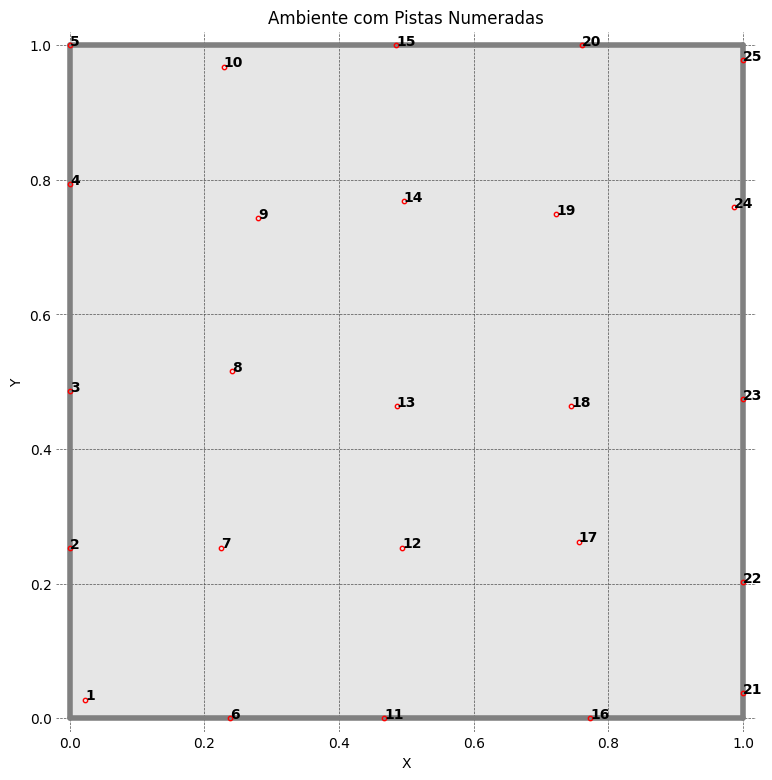

In [34]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i+1, xy=Env.objects['objects'][i],fontweight='bold', fontsize=10)
Env.plot_environment(gridlines=True, fig=fig, ax=ax,) #visualises current environment with walls and objects
plt.title('Ambiente com Pistas Numeradas')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

In [35]:
# Agent()

In [38]:
# help(Agent)

## define Ag

In [40]:
Ag = Agent(Environment=Env, params={'speed_mean':0.08,})

# agent configs
# Ag.pos = start_pos
Ag.thigmotaxis = 0.2

In [41]:
MINUTES = 60

### ag update

In [42]:
for i in range(int(MINUTES*60/Ag.dt)):
    Ag.update()

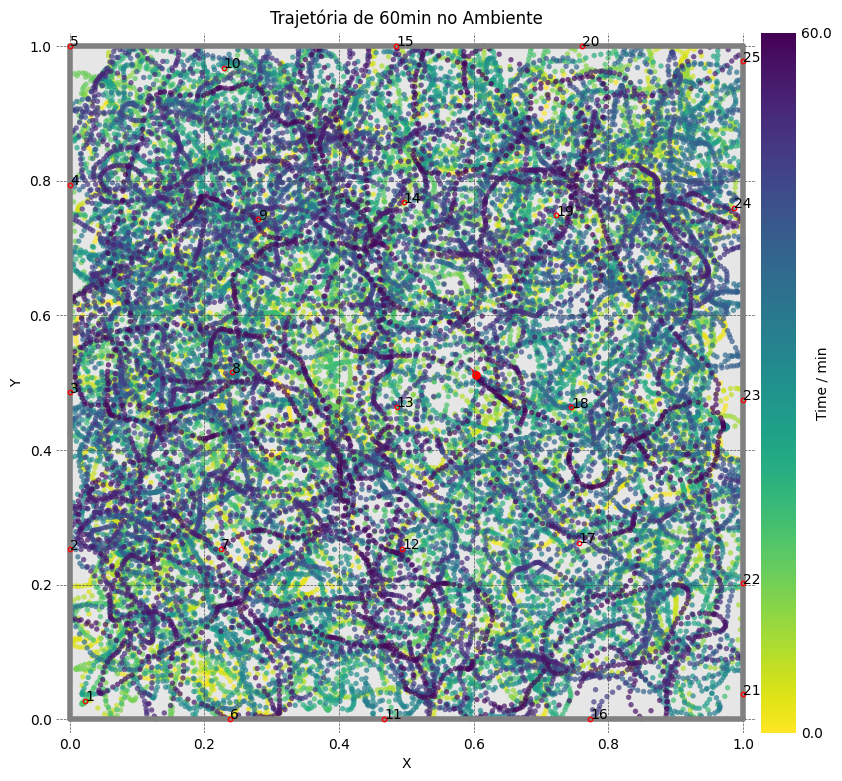

In [45]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i+1, xy=Env.objects['objects'][i], fontsize=10)
plt.title('Trajetória de 60min no Ambiente')
plt.ylabel('Y')
plt.xlabel('X')
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax)

plt.show()

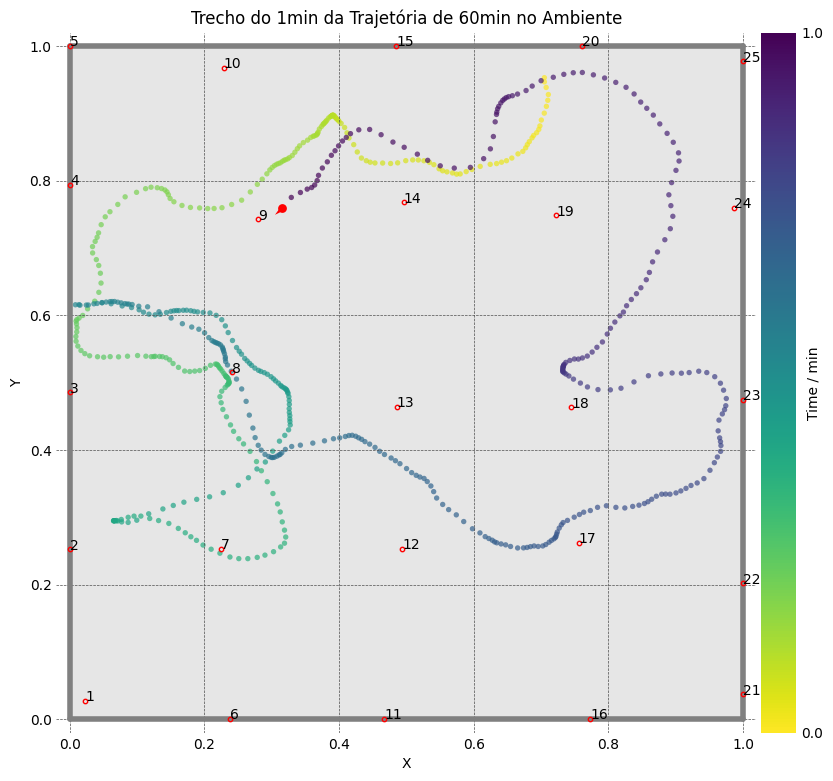

In [46]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i+1, xy=Env.objects['objects'][i], fontsize=10)
plt.title('Trecho do 1min da Trajetória de 60min no Ambiente')
plt.ylabel('Y')
plt.xlabel('X')
ax = Ag.plot_trajectory(t_start=0, t_end=60,
    color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax)

plt.show()

# init dfbase

In [47]:
dfbase = pd.DataFrame(Ag.history).copy()
print(dfbase.shape)
dfbase.head(2)

(72000, 6)


,t,pos,distance_travelled,vel,rot_vel,head_direction
0,0.05,"[0.704970144364569, 0.9530413646850322]",0.004665,"[0.0009373320219974168, -0.09328722713312088]",-2.420313,"[0.09062087751597683, -0.9958854635741172]"
1,0.10,"[0.7049853340729803, 0.9501922375456444]",0.007514,"[0.0003037941682260126, -0.05698254278775572]",-0.094187,"[0.06224145526686058, -0.998061120997238]"


In [48]:
df = dfbase.copy()
df.shape

(72000, 6)

## adding obj pos and names to dfbase

In [50]:
Env.objects.keys()

dict_keys(['objects', 'object_types', 'object_names'])

In [51]:
for i in range(NUM_OF_CUES):
    cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in df.index],
         f'obj_{i}_name':[Env.objects['object_names'][i] for _ in df.index],}
    cue_df = pd.DataFrame(data=cue_dict, index=df.index)  
    df = pd.concat([df, cue_df], axis=1)

In [43]:
# for i in range(NUM_OF_CUES):
#     cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in ap.index],
#          f'obj_{i}_name':[Env.objects['object_names'][i] for _ in ap.index]}
#     cue_ap = pd.DataFrame(data=cue_dict, index=ap.index)  
#     ap = pd.concat([ap, cue_ap], axis=1)
#     # df[f'obj_{i}_pos'] = [Env.objects['objects'][i] for _ in df.index]
#     # df[f'obj_{i}_name'] = [Env.objects['object_names'][i] for _ in df.index]

In [44]:
# ap.head()

In [45]:
# df.shape, ap.shape

In [52]:
df.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,obj_20_pos,obj_20_name,obj_21_pos,obj_21_name,obj_22_pos,obj_22_name,obj_23_pos,obj_23_name,obj_24_pos,obj_24_name
0,0.05,"[0.704970144364569, 0.9530413646850322]",0.004665,"[0.0009373320219974168, -0.09328722713312088]",-2.420313,"[0.09062087751597683, -0.9958854635741172]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX
1,0.10,"[0.7049853340729803, 0.9501922375456444]",0.007514,"[0.0003037941682260126, -0.05698254278775572]",-0.094187,"[0.06224145526686058, -0.998061120997238]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX


In [54]:
# ap.shape

## measure distances to objs

In [53]:
for i in range(NUM_OF_CUES):
    dist_cue_dict = {f'dist_to_obj_{i}': df.apply(apply_eucd_dist, axis=1, obj=i)}
    dist_cue_df = pd.DataFrame(data=dist_cue_dict, index=df.index)
    df = pd.concat([df, dist_cue_df], axis=1)

In [49]:
# for i in range(NUM_OF_CUES):
#     dist_cue_dict = {f'dist_to_obj_{i}': ap.apply(apply_eucd_dist, axis=1, obj=i)}
#     dist_cue_ap = pd.DataFrame(data=dist_cue_dict, index=ap.index)
#     ap = pd.concat([ap, dist_cue_ap], axis=1)

In [50]:
# ap.head()

In [51]:
# df.columns

In [52]:
# df[[feat for feat in df.columns if feat.startswith('dist_')]].mean()

In [262]:
# fig, ax = plt.subplots(1, 1, figsize=(14,7))
# for i in range(NUM_OF_CUES):
#     plt.annotate(text=i+1, xy=Env.objects['objects'][i], fontsize=10, fontweight='bold')
# ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, t_start=0, t_end=df['t'].max())

# plt.show()

In [55]:
obj_names = [Env.objects['object_names'][i] for i in range(NUM_OF_CUES)]
obj_dist_cols = [f'dist_to_obj_{i}' for i in range(NUM_OF_CUES)]

# def get_position_text(x):

In [56]:
apd['obj_0_pos'].values[0]

array([0.02256549, 0.02753175])

In [57]:
np.round(df['pos'].values[0], 3)

array([0.705, 0.953])

In [58]:
df['pos'] = [np.round(val, 3) for val in df['pos']]

In [59]:
df.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_15,dist_to_obj_16,dist_to_obj_17,dist_to_obj_18,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24
0,0.05,"[0.705, 0.953]",0.004665,"[0.0009373320219974168, -0.09328722713312088]",-2.420313,"[0.09062087751597683, -0.9958854635741172]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.955450,0.692876,0.491371,0.205174,0.072736,0.962748,0.807249,0.562733,0.341366,0.296006
1,0.10,"[0.705, 0.95]",0.007514,"[0.0003037941682260126, -0.05698254278775572]",-0.094187,"[0.06224145526686058, -0.998061120997238]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.952607,0.690033,0.488530,0.202334,0.074596,0.960031,0.804592,0.560301,0.339745,0.296236
2,0.15,"[0.705, 0.947]",0.010944,"[0.00023770911449672028, -0.06860405276492454]",-0.037387,"[0.04266567571934543, -0.9990894054665036]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.949185,0.686611,0.485110,0.198915,0.076920,0.956764,0.801397,0.557382,0.337820,0.296555
3,0.20,"[0.706, 0.942]",0.015799,"[0.029502752360550666, -0.09250023028684495]",6.105571,"[0.13075907218189456, -0.9914141743197593]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.944467,0.681891,0.480382,0.194183,0.079176,0.951909,0.796554,0.552678,0.334041,0.295598
4,0.25,"[0.708, 0.938]",0.019637,"[0.02256473148518623, -0.0733771338229583]",-0.208133,"[0.1857268547451898, -0.9826014122860088]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.940728,0.678150,0.476635,0.190436,0.081156,0.948071,0.792728,0.548971,0.331098,0.294936


## create positions

In [60]:
def apply_cps_to_positions(df, obj_dist_cols):
    dft = df[obj_dist_cols].T
    dft.columns = [f't_{i:08d}' for i in range(df.T.shape[1])]
    # order = [int(val.split('_')[-1]) for val in dft.sort_values(dft.columns[0]).index[:MAX_NUMBER_OF_CUES]]
    # dft.sort_values(dft.columns[0])

    positions_list = []
    mean_dist = []
    position_enc_list = []
    for feat in dft.columns:
        order = [int(val.split('_')[-1]) for val in dft.sort_values(feat).index[:MAX_NUMBER_OF_CUES]]
        dists = [val for val in dft.sort_values(feat)[feat][:MAX_NUMBER_OF_CUES]]
        mean_dist.append(np.mean(dists))
        positions_list.append(''.join([obj_names[i] for i in order]))
        # position_enc_list.append(np.hstack([objects_encode_list[i] for i in order]))

    # len(positions_list)


    pos_state_info_dict = {'position_state':[val for val in positions_list],
                           'mean_distance':[val for val in mean_dist]}
    pos_state_df = pd.DataFrame(data=pos_state_info_dict, index=df.index)
    return pd.concat([df, pos_state_df], axis=1).copy()

In [58]:
# ap.head()

In [59]:
# ap.shape

In [60]:
# df[obj_dist_cols].T

In [61]:
def apply_cps_to_positions_new(df, obj_dist_cols):
    """
    Para cada linha de df, ordena os objetos em obj_dist_cols
    pela distância até df['pos'], pega os MAX_NUMBER_OF_CUES
    mais próximos, e retorna position_state e mean_distance
    exatamente como sua versão original.
    
    Inputs:
    - df             : pd.DataFrame, com colunas 'pos' e obj_dist_cols
                       em que cada df[col] é um list-like [x,y].
    - obj_dist_cols  : List[str], nomes das colunas de objeto ex. ['obj_0_pos', ...]
    
    REQUER que existam no escopo global:
      MAX_NUMBER_OF_CUES : int
      obj_names          : List[str] de mesmo tamanho que obj_dist_cols
    """
    # 1) extrai array de posições do agente: shape (N, 2)
    pos_arr = np.vstack(df['pos'].values)  # cada entry é [x,y]
    
    # 2) empilha todas as posições de objetos: shape (N, M, 2)
    obj_pos_arr = np.stack([
        np.vstack(df[col].values) for col in obj_dist_cols
    ], axis=1)
    
    # 3) calcula distâncias euclidianas vetorizadas: shape (N, M)
    dists = np.linalg.norm(obj_pos_arr - pos_arr[:, None, :], axis=2)
    
    # 4) monta DataFrame de distâncias, para transpor como antes
    dist_df = pd.DataFrame(dists, columns=obj_dist_cols, index=df.index)
    dft = dist_df.T
    # renomeia colunas para 't_00000000' ... (igual à sua versão)
    dft.columns = [f't_{i:08d}' for i in range(df.shape[0])]

    # --- agora mantém o seu loop original ---
    positions_list = []
    mean_dist = []
    for feat in dft.columns:
        # pega os índices dos MAX_NUMBER_OF_CUES menores distâncias
        order = [
            int(val.split('_')[-1])
            for val in dft.sort_values(feat).index[:MAX_NUMBER_OF_CUES]
        ]
        # extrai as distâncias e faz a média
        dvals = dft.sort_values(feat)[feat][:MAX_NUMBER_OF_CUES].values
        mean_dist.append(dvals.mean())
        # concatena nomes
        positions_list.append(''.join(obj_names[i] for i in order))

    # monta o DataFrame de saída
    pos_state_info_dict = {
        'position_state': positions_list,
        'mean_distance': mean_dist
    }
    pos_state_df = pd.DataFrame(pos_state_info_dict, index=df.index)

    return pd.concat([df, pos_state_df], axis=1).copy()

In [62]:
# apd = apply_cps_to_positions_new(ap, obj_dist_cols)

In [63]:
# ap.columns

In [64]:
dfp = apply_cps_to_positions(df, obj_dist_cols)
dfp.shape

(72000, 83)

In [75]:
# ap.iloc[0:100_000].shape

In [76]:
# apd_2 = apply_cps_to_positions(ap.iloc[100_000:200_000], obj_dist_cols)

In [77]:
# for i in range(2, 11):
#     apd_2 = apply_cps_to_positions(ap.iloc[(i-1)*100_000:i*100_000], obj_dist_cols)
#     print(f"{(i-1)*100_000}:{i*100_000} pronto")
#     apd_2.to_parquet(f'apd{i}.gzip')

In [78]:
# ap.iloc[1_000_000:]

In [79]:
# apd = apply_cps_to_positions(ap.iloc[1_000_000:], obj_dist_cols)
# apd.shape

In [80]:
# apd.to_parquet(f'apd11.gzip')

## apd loop

In [ ]:
# apd_list = [pd.read_parquet(f'apd{i}.gzip') for i in range(1, 12)]


# # apd_full = pd.concat(apd_list, ignore_index=True)
# # apd_full.shape

In [52]:
# for i in range(2, 12):
#     print(f'apd{i}.gzip')

In [53]:
# apd_full = pd.concat(apd_list,)

In [54]:
# apd_full.shape

In [65]:
len(dfp), dfp['position_state'].nunique()/len(dfp), dfp['position_state'].nunique()

(72000, 0.013152777777777777, 947)

In [66]:
len(apd), apd['position_state'].nunique()/len(apd), apd['position_state'].nunique()

(1002001, 0.0010548891667772787, 1057)

In [67]:
apd.head()

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_17,dist_to_obj_18,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance
0,0.000,0.0,"[0.0, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.877006,1.040242,1.256338,1.000670,1.020126,1.106586,1.244571,1.398089,COQVSOAUMTASMTUPCRFN,0.266292
1,0.001,0.0,"[0.001, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.876157,1.039548,1.255733,0.999671,1.019146,1.105682,1.243779,1.397373,COQVSOAUMTASMTUPCRFN,0.265635
2,0.002,0.0,"[0.002, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.875308,1.038855,1.255128,0.998671,1.018166,1.104779,1.242987,1.396659,COQVSOAUMTASMTUPCRFN,0.264982
3,0.003,0.0,"[0.003, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.874460,1.038162,1.254524,0.997672,1.017186,1.103875,1.242195,1.395944,COQVSOAUMTASMTUPCRFN,0.264335
4,0.004,0.0,"[0.004, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.873612,1.037469,1.253921,0.996673,1.016205,1.102972,1.241404,1.395230,COQVSOAUMTASMTUPCRFN,0.263692


In [68]:
dfp.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_17,dist_to_obj_18,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance
0,0.05,"[0.075, 0.291]",0.004589,"[0.020077383331237042, -0.08956240169677332]",3.755528,"[0.0951163719204303, -0.9954661600439737]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.691073,0.792234,0.985721,0.959156,0.929045,0.942528,1.023959,1.151179,MTASMTUPHOBBCOQVDCTA,0.198953
1,0.10,"[0.077, 0.285]",0.011223,"[0.04348611720756651, -0.12534103546217645]",2.268371,"[0.17376774019080982, -0.9847866634296889]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.690558,0.794100,0.988733,0.955411,0.926295,0.941631,1.024910,1.153183,MTASMTUPHOBBCOQVDCTA,0.199044
2,0.15,"[0.08, 0.28]",0.017246,"[0.059986267943848426, -0.10446569086829949]",3.745991,"[0.28563240465789286, -0.9583392559054178]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.689032,0.794736,0.990454,0.951166,0.922850,0.939757,1.024686,1.153933,MTASMTUPHOBBCOQVDCTA,0.199250
3,0.20,"[0.083, 0.274]",0.024035,"[0.05253490845802872, -0.12519591758044957]",-2.478838,"[0.3198118024062174, -0.9474810874321906]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.688199,0.796334,0.993221,0.947041,0.919722,0.938502,1.025316,1.155641,MTASMTUPHOBBCOQVDCTA,0.199679
4,0.25,"[0.085, 0.268]",0.029794,"[0.04074430433207321, -0.1077406069781972]",-0.715154,"[0.33116289445883185, -0.9435735993199728]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.687749,0.797931,0.995785,0.943732,0.917284,0.937678,1.026089,1.157316,MTASMTUPHOBBCOQVDCTA,0.200196


In [79]:
apd[['pos','position_state_id']].sample(5)

,pos,position_state_id
608353,"[0.746, 0.607]",60
958690,"[0.733, 0.9570000000000001]",974
143864,"[0.721, 0.14300000000000002]",1028
847389,"[0.543, 0.846]",553
730126,"[0.397, 0.729]",537


In [67]:
num_unique_pos = dfp['position_state'].nunique()
num_unique_pos

947

In [68]:
apd['position_state_id'] = (apd.groupby('position_state').transform('ngroup'))
apd['normalized_position_state_id']  = (apd['position_state_id'] / num_unique_pos)
apd[['position_state', 'position_state_id', 'normalized_position_state_id']].sample(5)

,position_state,position_state_id,normalized_position_state_id
273621,MTUPIGAMCCOODCTASOAU,604,0.637804
268109,YGWPVLKJPIPZTSEHTKVX,1051,1.109820
610379,AOWPPIPZKDZDTSEHMOWW,61,0.064414
303393,MTASMTUPHOBBDCTACOQV,566,0.597677
717911,CEPVDCTAUOZFXSOPHOBB,202,0.213305


In [69]:
full_to_sample_position_state_to_id = {ps:idx for ps, idx in zip(apd['position_state'], apd['position_state_id'])}

In [70]:
apd[['X', 'Y','position_state_id', 'position_state']].sample(5)

,X,Y,position_state_id,position_state
678804,0.126,0.678,224,CEPVUOZFDCTAHOBBXSOP
434035,0.602,0.433,169,CCOOPIPZIGAMYGWPAOWP
266805,0.539,0.266,412,IGAMCCOOYGWPCRFNPIPZ
159358,0.199,0.159,676,MTUPSOAUMTASCOQVIGAM
580240,0.661,0.579,712,PIPZAOWPCCOOMOWWYGWP


In [71]:
count=0
for pos, ps in zip(dfp['pos'], dfp['position_state']):
    if ps not in full_to_sample_position_state_to_id:
        print(apd[(apd['X'] == pos[0])&(apd['Y'] == pos[1])][['pos','position_state', 'position_state_id']], pos)
        apd_id = apd[(apd['X'] == pos[0])&(apd['Y'] == pos[1])]['position_state_id'].values[0]
        print(ps)
        count+=1
        full_to_sample_position_state_to_id[ps] = apd_id


In [74]:
# dfp[dfp['position_state'] == 'IGAMPIPZYGWPCCOOTKVX']

In [75]:
# dfp[dfp['position_state'] == 'CEPVMOWWNFTUDCTAXSOP']

In [76]:
# apd[apd['position_state'].str.startswith('CEPVMOWWNFTU')]

In [263]:
# count

In [72]:
dfp['position_state_id'] = [full_to_sample_position_state_to_id[ps] for ps in dfp['position_state']]
dfp['normalized_position_state_id']  = (dfp['position_state_id'] / num_unique_pos)
dfp[['position_state_id', 'normalized_position_state_id']].sample(5)

,position_state_id,normalized_position_state_id
38486,830,0.876452
12416,950,1.003168
6204,635,0.670539
45763,654,0.690602
38296,456,0.481521


In [73]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()


In [74]:
apd['position_state_id'].nunique()

1057

In [76]:
apd['position_state_id'].value_counts()

position_state_id
360    9124
256    7707
930    7182
895    6928
928    6922
       ... 
917       1
679       1
259       1
51        1
740       1
Name: count, Length: 1057, dtype: int64

In [265]:
# sns.histplot(apd.groupby('position_state_id').size(), binwidth=1, binrange=(0, 50), stat='percent')
# plt.title('Histograma do Tamanho das Regiões')
# plt.xlabel('Tamanho ')
# plt.show()

In [81]:
point_area = 1e-6  # m² (0.001 * 0.001)

In [93]:
counts = (
    apd['position_state_id']
    .value_counts(dropna=False)
    .rename_axis('position_state_id')
    .reset_index(name='n_points')
)

# 3) Converta contagem em área e calcule percentual
counts['area_m2'] = counts['n_points'] * point_area
counts['area_cm2'] = counts['area_m2'] * 10_000
total_area = counts['area_m2'].sum()  # deve ser ~1.0 m² se cobre o quadrado todo
counts['percent'] = 100 * counts['area_m2'] / total_area

In [99]:
counts.head()

,position_state_id,n_points,area_m2,area_cm2,percent
0,360,9124,0.009124,91.24,0.910578
1,256,7707,0.007707,77.07,0.769161
2,930,7182,0.007182,71.82,0.716766
3,895,6928,0.006928,69.28,0.691416
4,928,6922,0.006922,69.22,0.690818


In [83]:
total_area

1.002001

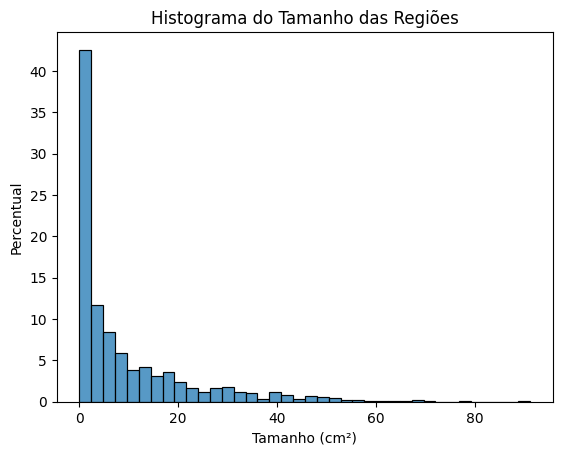

In [98]:
sns.histplot(counts, x='area_cm2',stat='percent')
plt.title('Histograma do Tamanho das Regiões')
plt.xlabel('Tamanho (cm²)')
plt.ylabel('Percentual')
plt.show()

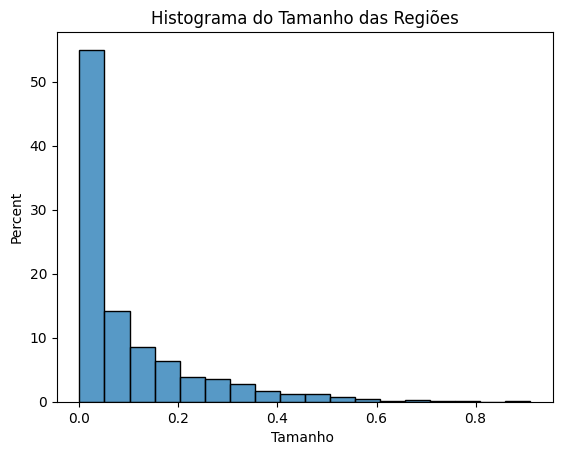

In [90]:
sns.histplot(counts, x='percent', stat='percent', binwidth=0.05)
plt.title('Histograma do Tamanho das Regiões')
plt.xlabel('Tamanho ')
plt.show()

In [100]:
counts[['area_cm2', 'area_m2', 'percent']].describe()

,area_cm2,area_m2,percent
count,1057.000000,1057.000000,1057.000000
mean,9.479669,0.000948,0.094607
std,13.100252,0.001310,0.130741
min,0.010000,0.000001,0.000100
25%,0.660000,0.000066,0.006587
50%,3.850000,0.000385,0.038423
75%,13.190000,0.001319,0.131637
max,91.240000,0.009124,0.910578


In [92]:
counts.sort_values('area_m2', ascending=False).head()

,position_state_id,n_points,area_m2,percent
0,360,9124,0.009124,0.910578
1,256,7707,0.007707,0.769161
2,930,7182,0.007182,0.716766
3,895,6928,0.006928,0.691416
4,928,6922,0.006922,0.690818


In [86]:
# apd.groupby('position_state_id').size()

In [101]:
apd.head()

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance,position_state_id,normalized_position_state_id
0,0.000,0.0,"[0.0, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.256338,1.000670,1.020126,1.106586,1.244571,1.398089,COQVSOAUMTASMTUPCRFN,0.266292,256,0.270327
1,0.001,0.0,"[0.001, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.255733,0.999671,1.019146,1.105682,1.243779,1.397373,COQVSOAUMTASMTUPCRFN,0.265635,256,0.270327
2,0.002,0.0,"[0.002, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.255128,0.998671,1.018166,1.104779,1.242987,1.396659,COQVSOAUMTASMTUPCRFN,0.264982,256,0.270327
3,0.003,0.0,"[0.003, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.254524,0.997672,1.017186,1.103875,1.242195,1.395944,COQVSOAUMTASMTUPCRFN,0.264335,256,0.270327
4,0.004,0.0,"[0.004, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.253921,0.996673,1.016205,1.102972,1.241404,1.395230,COQVSOAUMTASMTUPCRFN,0.263692,256,0.270327


In [85]:
# import seaborn as sns
# sns.histplot(apd.groupby('position_state_id'), binwidth=1, binrange=(0, 50), stat='percent')
# plt.title('Frequência das Regiões')
# plt.show()

In [102]:
# grupos_para_destacar = [1031, 739]
# plot_position_states(apd, grupos_para_destacar)

In [103]:
# import numpy as np
# import matplotlib.pyplot as plt
# import matplotlib.colors as mcolors

# def plot_position_states_imshow(apd, resolucao=100):
#     """
#     Plota o mapa completo de position_state_id usando imshow.
#     Cada grupo é pintado com uma cor única.
#     Um rótulo com o ID é anotado na posição média de cada grupo.

#     Parâmetros:
#     - apd: DataFrame com colunas X, Y, position_state_id
#     - resolucao: tamanho da grade (resolucao x resolucao)
#     """
#     # Converte X, Y para coordenadas discretas da grade
#     xs = (apd['X'] * (resolucao - 1)).astype(int)
#     ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)  # inverte Y para alinhar com o eixo da imagem

#     # Inicializa grade com valor inválido (-1)
#     mapa = np.full((resolucao, resolucao), -1, dtype=int)

#     # Preenche a grade com os position_state_id
#     for x, y, pid in zip(xs, ys, apd['position_state_id']):
#         mapa[y, x] = pid  # y = linha, x = coluna

#     # IDs únicos válidos (exclui -1)
#     unique_ids = np.unique(mapa)
#     unique_ids = unique_ids[unique_ids >= 0]

#     # Mapear IDs para índices de cor
#     id_to_idx = {pid: idx for idx, pid in enumerate(unique_ids)}
#     color_mapa = np.zeros_like(mapa)
#     for pid, idx in id_to_idx.items():
#         color_mapa[mapa == pid] = idx

#     # Cria colormap discreto
#     cmap = plt.cm.get_cmap('tab20', len(unique_ids))
#     norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, len(unique_ids) + 0.5), ncolors=cmap.N)

#     # Plot da imagem
#     plt.figure(figsize=(15, 15))
#     plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper', extent=[0, 1, 0, 1], interpolation='none')

#     # Anotar ponto médio de cada grupo
#     medias = apd.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
#     # for _, row in medias.iterrows():
#     #     plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
#     #                  fontsize=7, color='black', ha='center', va='center', fontweight='bold', alpha=0.8)

#     # Layout
#     plt.title("Mapa completo de position_state_id com anotações")
#     plt.xlabel("X")
#     plt.ylabel("Y")
#     plt.grid(False)
#     plt.gca().set_aspect('equal', adjustable='box')
#     plt.show()


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# import matplotlib.colors as mcolors
# import networkx as nx

# def plot_position_states_imshow_graph(apd, resolucao=100):
#     """
#     Plota o mapa completo de position_state_id usando imshow com coloração inteligente:
#     grupos vizinhos recebem cores diferentes.

#     Parâmetros:
#     - apd: DataFrame com colunas X, Y, position_state_id
#     - resolucao: tamanho da grade (resolucao x resolucao)
#     """
#     # Converte X, Y para coordenadas discretas da grade
#     xs = (apd['X'] * (resolucao - 1)).astype(int)
#     ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

#     # Inicializa grade com valor inválido (-1)
#     mapa = np.full((resolucao, resolucao), -1, dtype=int)

#     for x, y, pid in zip(xs, ys, apd['position_state_id']):
#         mapa[y, x] = pid  # y = linha, x = coluna

#     # IDs únicos válidos (exclui -1)
#     unique_ids = np.unique(mapa)
#     unique_ids = unique_ids[unique_ids >= 0]

#     # --- Construção do grafo de vizinhança ---
#     G = nx.Graph()
#     for i in range(resolucao - 1):
#         for j in range(resolucao - 1):
#             pid = mapa[i, j]
#             if pid == -1:
#                 continue
#             for di, dj in [(0, 1), (1, 0)]:
#                 ni, nj = i + di, j + dj
#                 if 0 <= ni < resolucao and 0 <= nj < resolucao:
#                     vizinho = mapa[ni, nj]
#                     if vizinho != -1 and vizinho != pid:
#                         G.add_edge(pid, vizinho)

#     # --- Colorização do grafo ---
#     color_map = nx.coloring.greedy_color(G, strategy='largest_first')
#     max_color = max(color_map.values()) + 1

#     # Mapeia position_state_id para índices de cor
#     pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

#     # Preenche o mapa de cores
#     color_mapa = np.zeros_like(mapa, dtype=int)
#     for pid in unique_ids:
#         idx = pid_to_color_idx[pid]
#         color_mapa[mapa == pid] = idx

#     # Colormap e normalização
#     cmap = plt.cm.get_cmap('tab20', max_color)
#     norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, max_color + 0.5), ncolors=cmap.N)

#     # --- Plot ---
#     plt.figure(figsize=(15, 15))
#     plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper',
#                extent=[0, 1, 0, 1], interpolation='none')

#     # Layout
#     plt.title("Mapa com coloração inteligente (grupos vizinhos com cores distintas)")
#     plt.xlabel("X")
#     plt.ylabel("Y")
#     plt.grid(False)
#     plt.gca().set_aspect('equal', adjustable='box')
#     plt.show()


In [97]:
# grupos_para_destacar = [2887, 1469, 1077]
# plot_position_states_imshow(apd,grupos_para_destacar)


In [104]:
# plot_position_states_imshow(apd)

In [264]:
# plot_position_states_imshow_graph(apd,)

In [105]:
# grupos_para_destacar = [1031, 739]
# plot_position_states(apd, grupos_para_destacar)

In [151]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import networkx as nx

def plot_position_states_with_objects(apd, Env, resolucao=100):
    """
    Plota o mapa de position_state_id com coloração inteligente para vizinhos
    e insere pontos de objetos sobrepostos via scatter (em preto).

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - Env: objeto com atributo Env.objects['objects'] (array Nx2 de coordenadas em [0,1])
    - resolucao: resolução da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

    # Inicializa grade
    mapa = np.full((resolucao, resolucao), -1, dtype=int)
    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid

    # IDs válidos
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # Grafo de vizinhança
    G = nx.Graph()
    for i in range(resolucao - 1):
        for j in range(resolucao - 1):
            pid = mapa[i, j]
            if pid == -1:
                continue
            for di, dj in [(0, 1), (1, 0)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < resolucao and 0 <= nj < resolucao:
                    vizinho = mapa[ni, nj]
                    if vizinho != -1 and vizinho != pid:
                        G.add_edge(pid, vizinho)

    # Colorir com greedy coloring
    color_map = nx.coloring.greedy_color(G, strategy='largest_first')
    max_color = max(color_map.values()) + 1
    pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

    # Construir mapa de cores
    color_mapa = np.zeros_like(mapa, dtype=int)
    for pid in unique_ids:
        color_mapa[mapa == pid] = pid_to_color_idx[pid]

    # Colormap e normalização
    cmap = plt.cm.get_cmap('tab20', max_color)
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, max_color + 0.5), ncolors=cmap.N)

    # --- Plot ---
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper',
               extent=[0, 1, 0, 1], interpolation='none')

    # Scatter de objetos
    objetos = Env.objects['objects'].copy()
    plt.scatter(objetos[:, 0], objetos[:, 1], color='black', s=20, label='Objetos')
    for i in range(len(objetos)):
        if Env.objects['object_names'][i] == 'NFTU':
            fixed_pos = objetos[i].copy()
            fixed_pos[1] = fixed_pos[1] - 0.02
            plt.annotate(Env.objects['object_names'][i], objetos[i] , fontsize=15, xytext=fixed_pos)
        else:
            plt.annotate(Env.objects['object_names'][i], objetos[i], fontsize=15)

    # Layout
    plt.title("Ambiente com Regiões e Objetos")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.legend()
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


/tmp/ipykernel_1108/3217003474.py:54: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


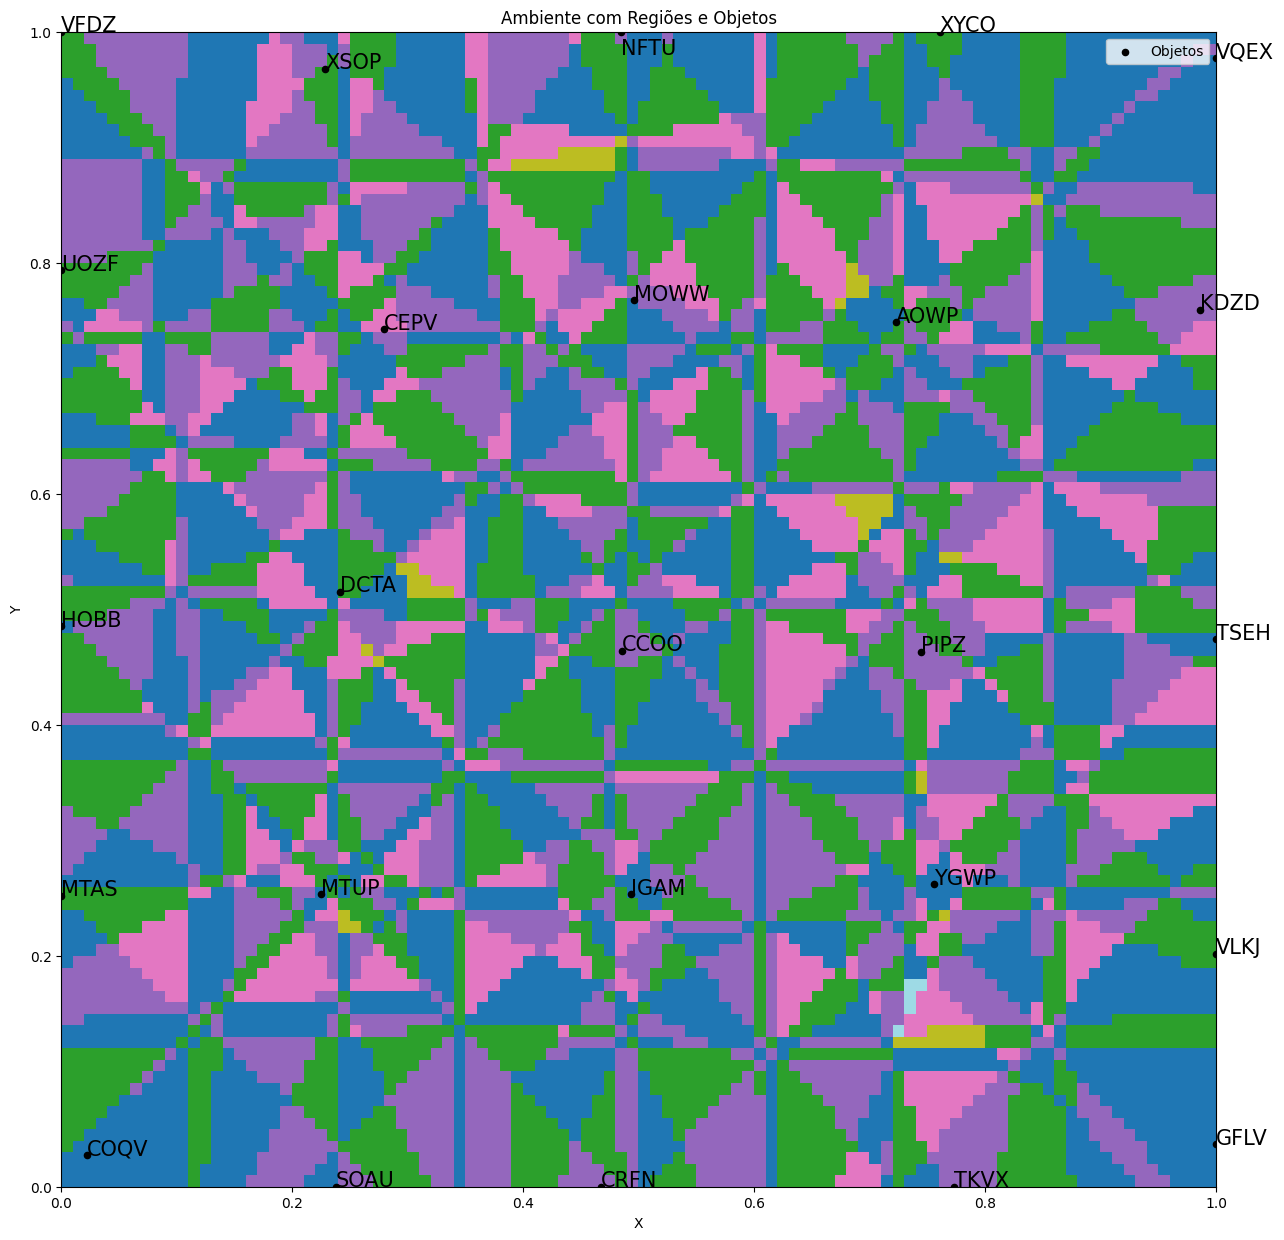

In [152]:
plot_position_states_with_objects(apd, Env)

In [153]:
# apd.head()

In [154]:
# apd[['obj_0_name', 'obj_0_pos']].values

In [202]:
def plot_with_highlighted_position_and_names(apd, Env, posicao, nomes_string, ps_id, resolucao=100):
    """
    Plota o mapa de position_state_id com objetos, destacando:
    - um ponto específico (posicao)
    - objetos cujo nome aparece em nomes_string (string de nomes separados por vírgula)

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - Env: objeto com Env.objects['objects'] (Nx2) e Env.objects['object_names'] (N)
    - posicao: tupla (x, y) no espaço [0, 1]
    - nomes_string: string com nomes separados por vírgula ou espaço (ex: 'obj1,obj2')
    - resolucao: resolução da grade
    """
    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib.colors as mcolors
    import networkx as nx

    # Converte X, Y para coordenadas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

    mapa = np.full((resolucao, resolucao), -1, dtype=int)
    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid

    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # Grafo de vizinhança
    G = nx.Graph()
    for i in range(resolucao - 1):
        for j in range(resolucao - 1):
            pid = mapa[i, j]
            if pid == -1:
                continue
            for di, dj in [(0, 1), (1, 0)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < resolucao and 0 <= nj < resolucao:
                    vizinho = mapa[ni, nj]
                    if vizinho != -1 and vizinho != pid:
                        G.add_edge(pid, vizinho)

    # Colorir
    color_map = nx.coloring.greedy_color(G, strategy='largest_first')
    max_color = max(color_map.values()) + 1
    pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

    color_mapa = np.zeros_like(mapa, dtype=int)
    for pid in unique_ids:
        color_mapa[mapa == pid] = pid_to_color_idx[pid]

    # Plot
    plt.figure(figsize=(15, 15))
    cmap = plt.cm.get_cmap('tab20', max_color)
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, max_color + 0.5), ncolors=cmap.N)
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper',
               extent=[0, 1, 0, 1], interpolation='none')

    # Objetos e nomes destacados
    objetos = Env.objects['objects']
    nomes = Env.objects['object_names']

    # Normalização de nomes recebidos
    nomes_alvo = list(nomes_string[i:i+4] for i in range(0, len(nomes_string), 4))
    print(nomes_alvo)
    for i, nome in enumerate(nomes):
        obj_xy = objetos[i]
        if nome in nomes_alvo:
            # objeto destacado
            plt.scatter(obj_xy[0], obj_xy[1], color='red', s=100, label='Destacado' if i == 0 else "")
            plt.annotate(nome, obj_xy, fontsize=13, color='black', ha='center', va='bottom')
        else:
            # objeto normal
            plt.scatter(obj_xy[0], obj_xy[1], color='black', s=40)
            plt.annotate(nome, obj_xy, fontsize=10, color='black', ha='center', va='bottom')

    # Ponto fornecido
    if posicao is not None:
        plt.scatter(posicao[0], posicao[1], color='blue', s=100, marker='X', label='Posição marcada')
        plt.annotate("Posição", posicao, fontsize=12, color='blue', ha='center', va='top')

    # Layout
    rounded_posicao = np.round(posicao, 3)
    plt.suptitle(f"Exemplo de Position State \n (x, y) = {rounded_posicao} \n Position State = {'-'.join(nomes_alvo)} \n Position State ID = {ps_id}")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.legend(loc='upper left')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


/tmp/ipykernel_1108/186473844.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


['XYCO', 'AOWP', 'NFTU', 'MOWW', 'VQEX']


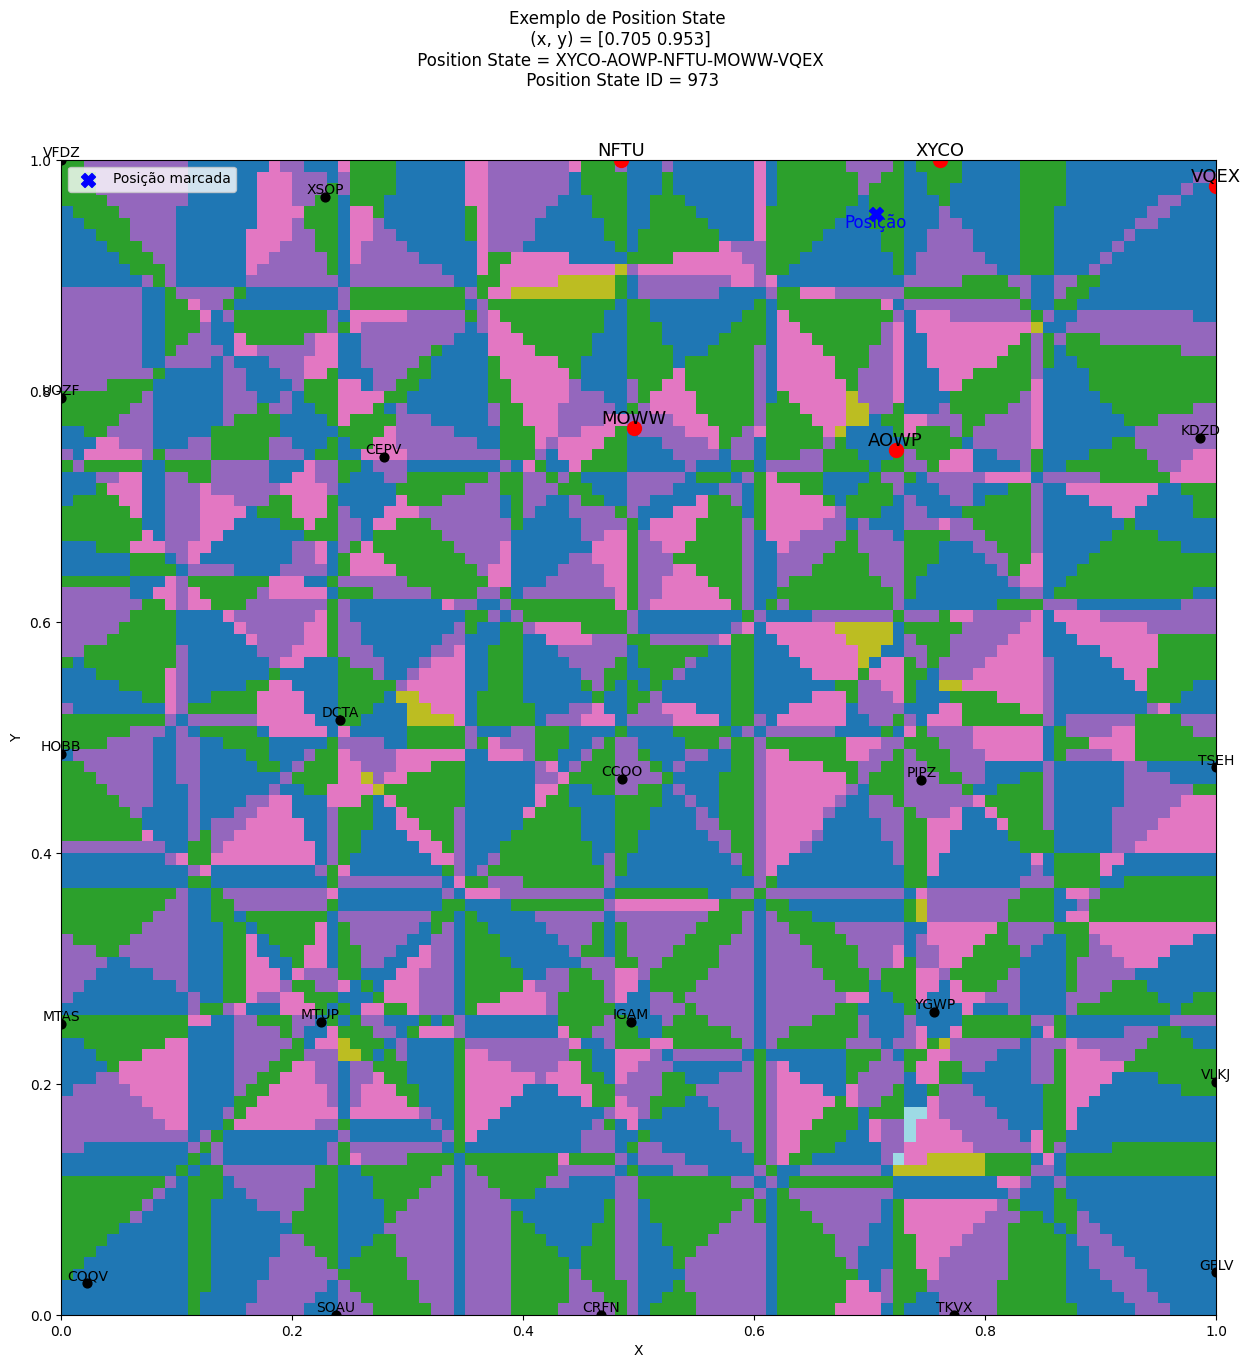

In [203]:
pos = dfp['pos'].values[0]
nomes = dfp['position_state'].values[0]
ps_id = dfp['position_state_id'].values[0]
plot_with_highlighted_position_and_names(apd, Env, posicao=pos, nomes_string=nomes,ps_id = ps_id)

In [204]:
# dfp.head()

In [103]:
# apd.head()

## get change of pos

In [205]:
dfp['last_position_state_id'] = (dfp['position_state_id'].shift(1))
dfp.shape

(72000, 86)

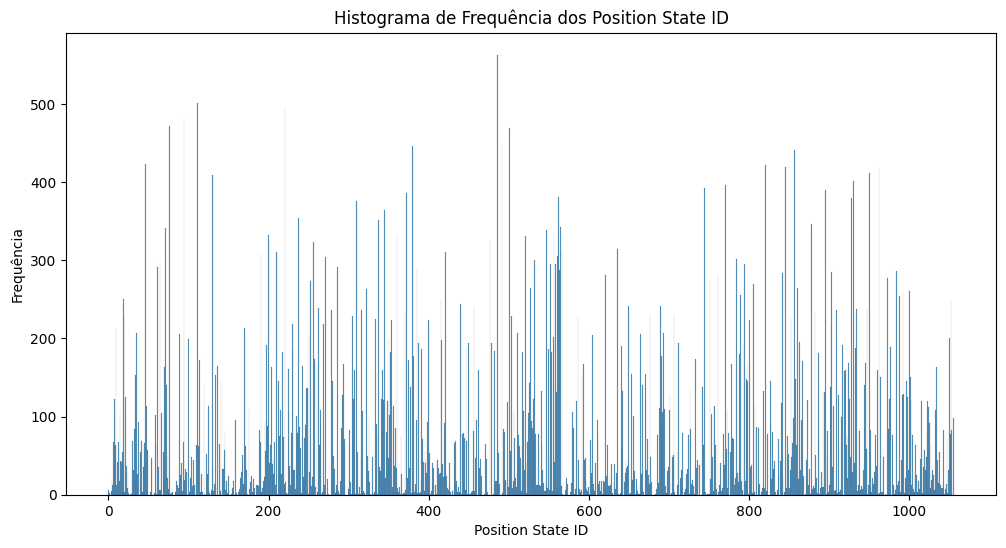

In [217]:
fig, ax = plt.subplots(figsize=(12, 6))
plt.title('Histograma de Frequência dos Position State ID')
sns.histplot(dfp['position_state_id'],binwidth=1,)
plt.ylabel('Frequência')
plt.xlabel('Position State ID')
plt.show()

In [ ]:
step_time = 0.05 # 0.05s

In [226]:
dfp.groupby('position_state_id')['t'].nunique().describe()*0.05

count    47.350000
mean      3.801478
std       4.916473
min       0.050000
25%       0.400000
50%       1.700000
75%       5.250000
max      28.150000
Name: t, dtype: float64

In [227]:
# dfp.groupby()

In [218]:
# plt.hist(dfp['position_state_id'])

In [266]:
# sns.histplot(dfp.groupby(['position_state_id'], as_index=False).size())

In [228]:
# dfp['position_state_id'].value_counts(normalize=True,).hist(grid=False)

In [229]:
# dfp[['position_state', 'position_state_id', 'last_position_state_id',]].iloc[8:12]

In [230]:
# dfp[['position_state_id', 'last_position_state_id']].dtypes

In [231]:
# dfp.shape

In [232]:
# len(dfp['position_state_id'])

In [233]:
change_dict_ = {'change_of_position_state':[int(pos!=last_pos) for pos, last_pos in zip(dfp['position_state_id'].astype('float'), dfp['last_position_state_id'])]}
change_dict_df = pd.DataFrame(change_dict_)

print(change_dict_df.shape)
# dfp = pd.concat([dfp, change_dict_df], ignore_index=True, axis=0)

(72000, 1)


In [234]:
dfp.shape

(72000, 86)

In [235]:
dfp['change_of_position_state'] = (change_dict_df['change_of_position_state'])

In [236]:
dfp.shape

(72000, 87)

In [175]:
# dfp['change_of_position_state'].values

In [237]:
dfp[['position_state', 'position_state_id', 'last_position_state_id', 'change_of_position_state']].iloc[8:12]

,position_state,position_state_id,last_position_state_id,change_of_position_state
8,XYCOAOWPNFTUMOWWVQEX,973,973.0,0
9,XYCOAOWPNFTUMOWWVQEX,973,973.0,0
10,XYCOAOWPNFTUMOWWVQEX,973,973.0,0
11,XYCOAOWPNFTUMOWWVQEX,973,973.0,0


In [238]:
dfp[dfp['change_of_position_state'] == 1][['position_state_id', 'last_position_state_id', 'change_of_position_state']].head()

,position_state_id,last_position_state_id,change_of_position_state
0,973,NaN,1
14,968,973.0,1
15,967,968.0,1
17,76,967.0,1
34,46,76.0,1


In [239]:
dfp[dfp['change_of_position_state'] == 1].shape

(13135, 87)

In [240]:
dfp['change_of_position_state'].mean()

0.18243055555555557

# train df

In [241]:
dfc = dfp[dfp['change_of_position_state'] == 1].iloc[1:].reset_index(drop=True).copy()
dfc.shape

(13134, 87)

In [242]:
dfc.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.75,"[0.7, 0.89]",0.070249,"[-0.04648240511472945, -0.103916968250235]",-0.721635,"[-0.3147863504974622, -0.949162553802292]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.750764,0.512796,0.314111,0.311944,XYCOAOWPMOWWNFTUVQEX,0.212126,968,1.022175,973.0,1
1,0.80,"[0.699, 0.885]",0.075165,"[-0.02934323295077368, -0.09384195961539277]",2.351097,"[-0.3093471255142001, -0.9509491868318211]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.747054,0.509860,0.313531,0.314688,XYCOAOWPMOWWNFTUKDZD,0.211975,967,1.021119,968.0,1


In [243]:
dfc.columns

Index(['t', 'pos', 'distance_travelled', 'vel', 'rot_vel', 'head_direction',
       'obj_0_pos', 'obj_0_name', 'obj_1_pos', 'obj_1_name', 'obj_2_pos',
       'obj_2_name', 'obj_3_pos', 'obj_3_name', 'obj_4_pos', 'obj_4_name',
       'obj_5_pos', 'obj_5_name', 'obj_6_pos', 'obj_6_name', 'obj_7_pos',
       'obj_7_name', 'obj_8_pos', 'obj_8_name', 'obj_9_pos', 'obj_9_name',
       'obj_10_pos', 'obj_10_name', 'obj_11_pos', 'obj_11_name', 'obj_12_pos',
       'obj_12_name', 'obj_13_pos', 'obj_13_name', 'obj_14_pos', 'obj_14_name',
       'obj_15_pos', 'obj_15_name', 'obj_16_pos', 'obj_16_name', 'obj_17_pos',
       'obj_17_name', 'obj_18_pos', 'obj_18_name', 'obj_19_pos', 'obj_19_name',
       'obj_20_pos', 'obj_20_name', 'obj_21_pos', 'obj_21_name', 'obj_22_pos',
       'obj_22_name', 'obj_23_pos', 'obj_23_name', 'obj_24_pos', 'obj_24_name',
       'dist_to_obj_0', 'dist_to_obj_1', 'dist_to_obj_2', 'dist_to_obj_3',
       'dist_to_obj_4', 'dist_to_obj_5', 'dist_to_obj_6', 'dist_to_obj_7'

In [244]:
columns_to_keep = [
    't',
    'pos',
    'distance_travelled',
    'vel',
    'rot_vel',
    'head_direction',
    'position_state',
    'position_state_id',
    'normalized_position_state_id',
    'last_position_state_id',
    'change_of_position_state',
]

### save dfc

In [273]:
save_dfc = False

In [272]:
# print(dfc[columns_to_keep].shape)
if save_dfc:
    dfc[columns_to_keep].to_parquet(r'/home/mgteus/workspace/navitrans/bert_trainset_squared_25.gzip', index=False)

In [245]:
dfc[columns_to_keep].head(5)

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.75,"[0.7, 0.89]",0.070249,"[-0.04648240511472945, -0.103916968250235]",-0.721635,"[-0.3147863504974622, -0.949162553802292]",XYCOAOWPMOWWNFTUVQEX,968,1.022175,973.0,1
1,0.80,"[0.699, 0.885]",0.075165,"[-0.02934323295077368, -0.09384195961539277]",2.351097,"[-0.3093471255142001, -0.9509491868318211]",XYCOAOWPMOWWNFTUKDZD,967,1.021119,968.0,1
2,0.90,"[0.698, 0.879]",0.081759,"[-0.014781629317759393, -0.04886508440626436]",-2.718846,"[-0.2694234454470962, -0.9630218102636179]",AOWPXYCOMOWWNFTUKDZD,76,0.080253,967.0,1
3,1.75,"[0.666, 0.84]",0.133414,"[-0.07658095338432869, -0.03239162333011025]",-3.094691,"[-0.7753741537587893, -0.6315021153431248]",AOWPMOWWXYCONFTUKDZD,46,0.048574,76.0,1
4,2.20,"[0.63, 0.825]",0.172443,"[-0.07400184852546676, -0.006027612039467556]",-2.263985,"[-0.9719050362633794, -0.23537332152535723]",AOWPMOWWXYCONFTUCEPV,45,0.047518,46.0,1


In [246]:
dfc['position_state'].values[:3]

array(['XYCOAOWPMOWWNFTUVQEX', 'XYCOAOWPMOWWNFTUKDZD',
       'AOWPXYCOMOWWNFTUKDZD'], dtype=object)

# apd vizz

In [275]:
def plot_position_states_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # pontos não destacados
    s_outros: int = 10,
    s_destacados: int = 28,
    annotate: bool = True,
    cmap_name: str = "viridis",
):
    """
    Plota os pontos do DataFrame 'apd' (colunas: X, Y, position_state_id),
    destacando 'grupos_destacados' com cores oriundas do colormap viridis,
    respeitando a ordem de aparecimento na lista:

    - ids ANTERIORES: recebem as primeiras cores do colormap, na ordem.
    - id ÚLTIMO: recebe a cor final do colormap (mais destacada).
    - Anotações (labels) sempre em preto.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - grupos_destacados: lista ordenada de ids (ordem define a sequência de cores)
    - title: título opcional
    - cor_outros, s_outros: cor e tamanho dos pontos não-destacados
    - s_destacados: tamanho dos pontos destacados
    - annotate: desenhar anotações das médias por grupo
    - cmap_name: nome do colormap (default 'viridis')
    """

    if not {"X", "Y", "position_state_id"}.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # Remove duplicados preservando a ordem
    ordem_unica = list(dict.fromkeys(grupos_destacados))
    n = len(ordem_unica)

    plt.figure(figsize=(12, 12))

    # 1) Plota todos os pontos não destacados
    destaque_mask = apd["position_state_id"].isin(ordem_unica)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    if n > 0:
        cmap = cm.get_cmap(cmap_name, max(n, 2))

        # Mapeia cores: anteriores = cmap(0..n-2), último = cmap(n-1)
        anteriores_ids = ordem_unica[:-1]
        ultimo_id = ordem_unica[-1]

        # --- Anteriores (na ordem, cada um com sua cor do viridis) ---
        for i, gid in enumerate(anteriores_ids):
            cor_i = cmap(i / (max(n - 1, 1)))  # normaliza 0..1 mesmo quando n-1 = 1
            grp = apd[apd["position_state_id"] == gid]
            if not grp.empty:
                plt.scatter(
                    grp["X"], grp["Y"],
                    color=cor_i, s=s_destacados,
                    label=None if i else "Destacados (anteriores)",
                    zorder=2
                )

        # --- Último (usa a ponta do colormap) ---
        grp_last = apd[apd["position_state_id"] == ultimo_id]
        if not grp_last.empty:
            cor_last = cmap(1.0)  # última cor do viridis
            plt.scatter(
                grp_last["X"], grp_last["Y"],
                color=cor_last, s=s_destacados,
                label="Destacado (último)",
                zorder=3
            )

        # --- Anotações (sempre em preto) ---
        if annotate:
            medias = apd[apd["position_state_id"].isin(ordem_unica)] \
                        .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
            for _, row in medias.iterrows():
                plt.annotate(
                    str(row["position_state_id"]),
                    (row["X"], row["Y"]),
                    fontsize=8, alpha=0.95,
                    ha="center", va="center",
                    fontweight="bold",
                    color="black",  # sempre preto
                    zorder=4
                )

    # Layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title if title else "Grupos destacados por position_state_id (viridis por ordem)")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")

    # Legenda enxuta, se houver algo além de "Outros"
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        # remove duplicatas mantendo ordem
        seen = set()
        uniq_handles, uniq_labels = [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_handles.append(h)
                uniq_labels.append(l)
                seen.add(l)
        plt.legend(uniq_handles, uniq_labels, loc="best")

    # Não chama plt.show(); quem usa decide salvar/mostrar

In [276]:
plot_position_states_w_title(apd, [260, 447])

: 

# FIM